<a href="https://colab.research.google.com/github/KCGSPerera/CM2604-Telco-Customer-Churn/blob/main/CM2604_Telco_Customer_Churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CM2604 Machine Learning Coursework — Part 1

Student name:
Student ID:

Objective:
Predict customer churn using KNN, Logistic Regression,
and Random Forest, and compare their performance.

Dataset: Telco Customer Churn
Dataset source: To be recorded when downloaded

Reproducibility:
Use a fixed random seed of 42 for applicable experiments.

AI assistance:
ChatGPT is being used to support planning, implementation,
explanation, and report preparation. Exact prompts, dates,
uses, and verification will be recorded in a separate AI-use log.



In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

RANDOM_STATE = 42

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("Setup successful")

Python: 3.13.18
pandas: 2.2.3
NumPy: 2.4.6
scikit-learn: 1.6.1
Setup successful


## Dataset provenance

Dataset: Telco Customer Churn
Source: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
Downloaded on: [enter your actual download date]
Original filename: WA_Fn-UseC_-Telco-Customer-Churn.csv

Target: Churn
Yes = customer left the service
No = customer remained with the service

The original CSV is preserved without modification.

3. Upload and load the CSV

In [2]:
from google.colab import files
import io
import hashlib

uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:
filename = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

raw_bytes = uploaded[filename]
df_raw = pd.read_csv(io.BytesIO(raw_bytes))

# Work on a copy while preserving the original data.
df = df_raw.copy()

print("Dataset shape:", df.shape)
print("File SHA-256:", hashlib.sha256(raw_bytes).hexdigest())

display(df.head())

Dataset shape: (7043, 21)
File SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


4. Check its structure

In [5]:
print("COLUMN TYPES")
df.info()

print("\nTARGET COUNTS")
print(df["Churn"].value_counts(dropna=False))

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nDUPLICATE CUSTOMER IDs")
print(df["customerID"].duplicated().sum())

print("\nMISSING VALUES DETECTED BY PANDAS")
print(df.isna().sum())

COLUMN TYPES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-nu

5. Check blank strings and invalid charges

## Data quality checks

Check for blank text values and investigate why TotalCharges
is stored as text. Preserve the original dataset and record
any changes before modelling.

In [6]:
# Find empty strings or strings containing only whitespace.
text_columns = df.select_dtypes(include=["object", "string"]).columns

blank_counts = df[text_columns].apply(
    lambda column: column.str.strip().eq("").sum()
)

print("BLANK STRING COUNTS")
print(blank_counts[blank_counts > 0])

# Attempt conversion without changing the dataframe yet.
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

invalid_charge_mask = total_charges_numeric.isna()

print("\nTOTAL CHARGES VALUES THAT CANNOT BE PARSED")
print("Count:", invalid_charge_mask.sum())

display(
    df.loc[
        invalid_charge_mask,
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

print("\nRAW VALUES — repr() makes whitespace visible")
print(
    df.loc[invalid_charge_mask, "TotalCharges"]
      .map(repr)
      .value_counts()
)

BLANK STRING COUNTS
TotalCharges    11
dtype: int64

TOTAL CHARGES VALUES THAT CANNOT BE PARSED
Count: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No



RAW VALUES — repr() makes whitespace visible
TotalCharges
' '    11
Name: count, dtype: int64


6. Convert the column and reserve the test set

In [7]:
from sklearn.model_selection import train_test_split

# Deterministic type conversion; no statistics are learned here.
df["TotalCharges"] = total_charges_numeric

# Confirm the target contains only the expected labels.
assert set(df["Churn"].unique()) == {"Yes", "No"}

# Exclude the identifier and target from model inputs.
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining churn percentages")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTest churn percentages")
print(y_test.value_counts(normalize=True).mul(100).round(2))

# Keep a training-only dataframe for exploratory analysis.
train_eda = X_train.copy()
train_eda["Churn"] = y_train.map({0: "No", 1: "Yes"})

Training set: (5634, 19)
Test set: (1409, 19)

Training churn percentages
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

Test churn percentages
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


7. Summarise the training data

## Exploratory data analysis — training data

Exploratory analysis uses only the training partition.
The held-out test partition is reserved for final evaluation.

The initial audit identified 11 blank TotalCharges values,
all associated with zero tenure. These were converted to
missing numeric values, and the affected records were retained.
Imputation will be fitted within the modelling pipelines.

In [9]:
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]

print("TRAINING DATA — NUMERIC SUMMARY")
display(train_eda[numeric_features].describe().round(2))

print("\nTRAINING DATA — MISSING VALUES")
print(train_eda.isna().sum().loc[lambda counts: counts > 0])

print("\nTRAINING DATA — CATEGORICAL VALUES")
categorical_features = [
    column for column in X_train.columns
    if column not in numeric_features
]

for column in categorical_features:
    print(f"\n{column}:")
    print(train_eda[column].value_counts(dropna=False))

TRAINING DATA — NUMERIC SUMMARY


,tenure,MonthlyCharges,TotalCharges
count,5634.00,5634.00,5626.00
mean,32.49,64.93,2302.60
std,24.57,30.14,2279.17
min,0.00,18.40,18.85
25%,9.00,35.66,407.28
50%,29.00,70.50,1398.12
75%,55.00,90.00,3838.61
max,72.00,118.75,8684.80



TRAINING DATA — MISSING VALUES
TotalCharges    8
dtype: int64

TRAINING DATA — CATEGORICAL VALUES

gender:
gender
Male      2833
Female    2801
Name: count, dtype: int64

SeniorCitizen:
SeniorCitizen
0    4714
1     920
Name: count, dtype: int64

Partner:
Partner
No     2905
Yes    2729
Name: count, dtype: int64

Dependents:
Dependents
No     3955
Yes    1679
Name: count, dtype: int64

PhoneService:
PhoneService
Yes    5075
No      559
Name: count, dtype: int64

MultipleLines:
MultipleLines
No                  2685
Yes                 2390
No phone service     559
Name: count, dtype: int64

InternetService:
InternetService
Fiber optic    2483
DSL            1937
No             1214
Name: count, dtype: int64

OnlineSecurity:
OnlineSecurity
No                     2797
Yes                    1623
No internet service    1214
Name: count, dtype: int64

OnlineBackup:
OnlineBackup
No                     2442
Yes                    1978
No internet service    1214
Name: count, dtype: int64

D

8. Create the first EDA charts

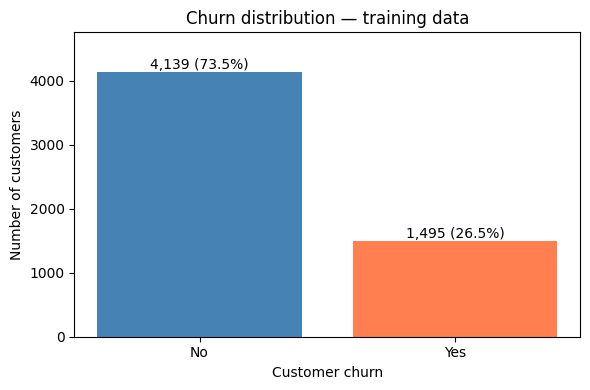

In [10]:
# Chart 1: training target distribution
counts = train_eda["Churn"].value_counts().reindex(["No", "Yes"])

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index, counts.values, color=["steelblue", "coral"])

for bar, count in zip(bars, counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count,
        f"{count:,} ({count / counts.sum():.1%})",
        ha="center",
        va="bottom"
    )

ax.set(
    title="Churn distribution — training data",
    xlabel="Customer churn",
    ylabel="Number of customers"
)
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

9. compare numeric features between churners and non-churners

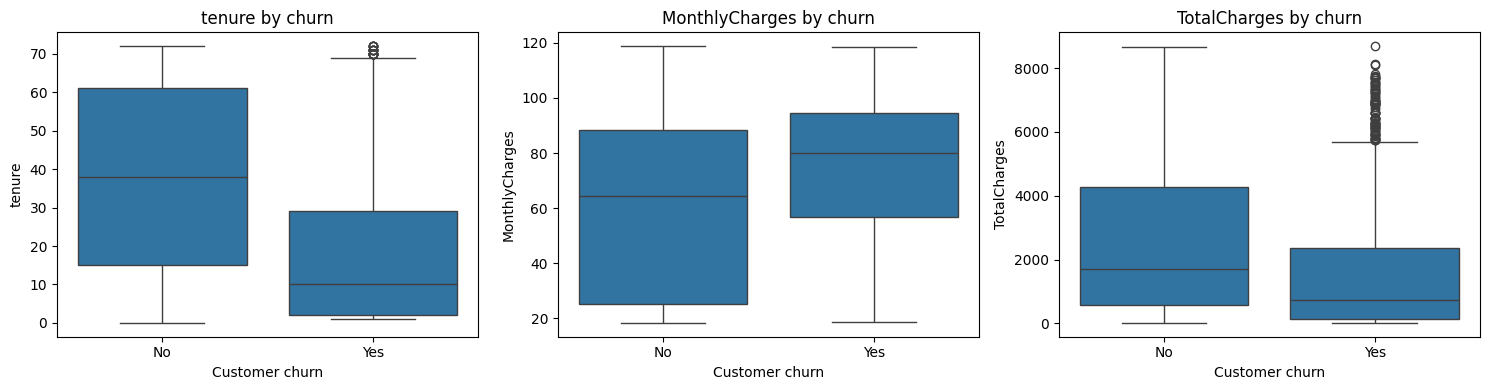

MEDIANS BY CHURN — TRAINING DATA


,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.40,1691.9
Yes,10.0,79.95,740.3


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(axes, numeric_features):
    sns.boxplot(
        data=train_eda,
        x="Churn",
        y=column,
        order=["No", "Yes"],
        ax=ax
    )
    ax.set_title(f"{column} by churn")
    ax.set_xlabel("Customer churn")

plt.tight_layout()
plt.show()

print("MEDIANS BY CHURN — TRAINING DATA")
display(
    train_eda.groupby("Churn")[numeric_features]
             .median()
             .reindex(["No", "Yes"])
             .round(2)
)

10. Compare churn rates across customer groups

## Churn rates across categorical groups

Compare the percentage of customers who churn within each
category using training data only. Include group sizes to
provide context for the percentages.

These comparisons describe associations and do not establish
causal relationships.

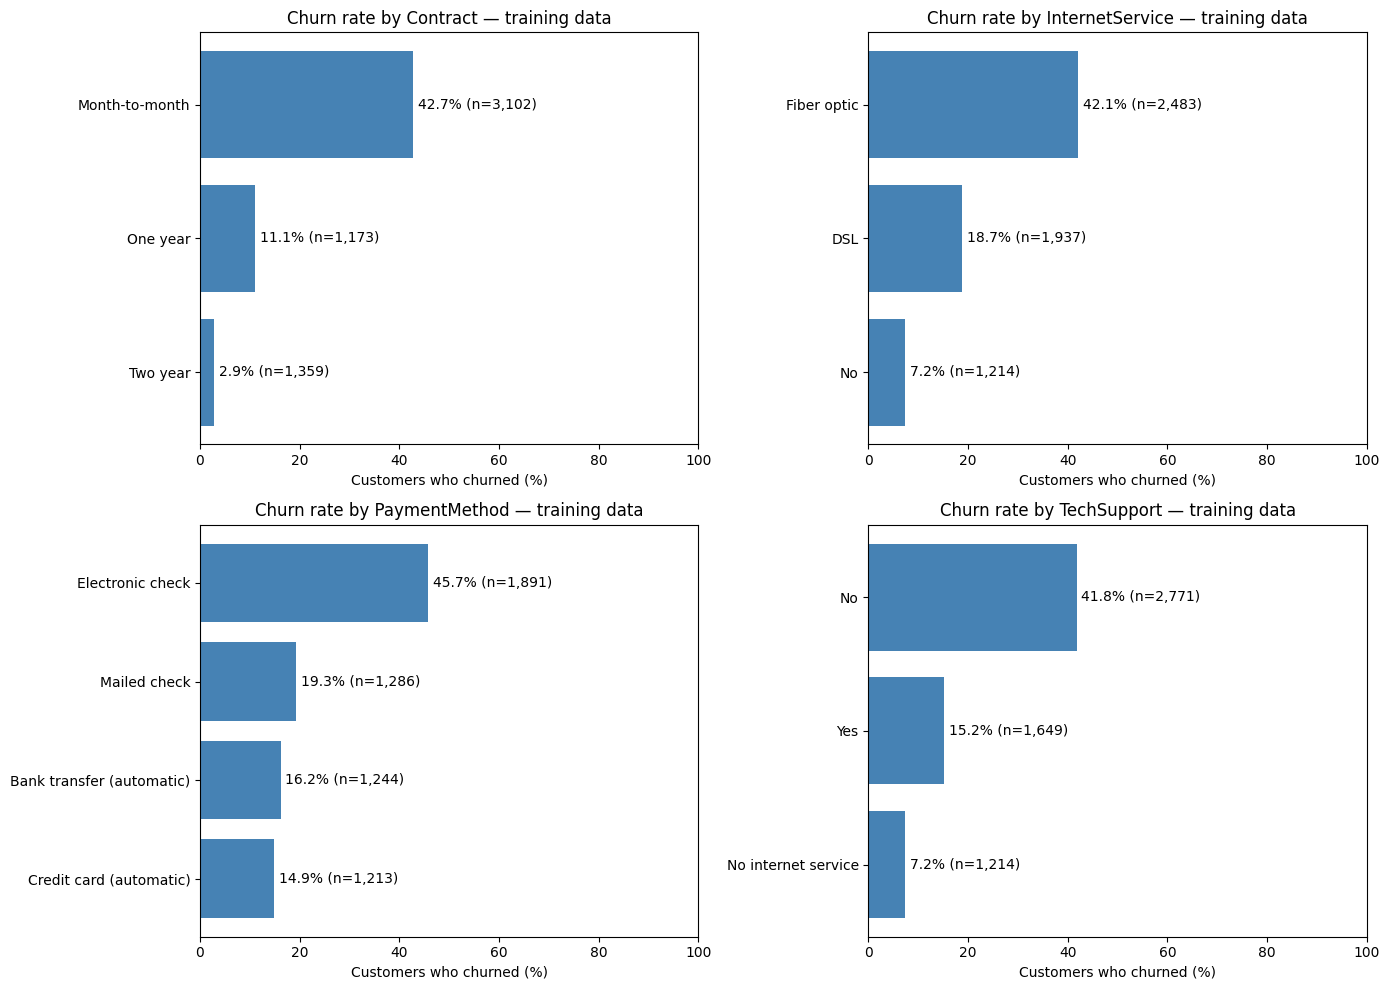


CHURN BY CONTRACT


,customers,churners,churn_rate_pct
Contract,,,
Month-to-month,3102,1326,42.75
One year,1173,130,11.08
Two year,1359,39,2.87



CHURN BY INTERNETSERVICE


,customers,churners,churn_rate_pct
InternetService,,,
Fiber optic,2483,1045,42.09
DSL,1937,362,18.69
No,1214,88,7.25



CHURN BY PAYMENTMETHOD


,customers,churners,churn_rate_pct
PaymentMethod,,,
Electronic check,1891,865,45.74
Mailed check,1286,248,19.28
Bank transfer (automatic),1244,201,16.16
Credit card (automatic),1213,181,14.92



CHURN BY TECHSUPPORT


,customers,churners,churn_rate_pct
TechSupport,,,
No,2771,1157,41.75
Yes,1649,250,15.16
No internet service,1214,88,7.25


In [12]:
features_to_compare = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport"
]

category_churn_tables = {}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, feature in zip(axes.flat, features_to_compare):

    summary = (
        train_eda.groupby(feature, observed=True)["Churn"]
        .agg(
            customers="size",
            churners=lambda values: values.eq("Yes").sum()
        )
    )

    summary["churn_rate_pct"] = (
        summary["churners"] / summary["customers"] * 100
    )

    summary = summary.sort_values(
        "churn_rate_pct", ascending=False
    )

    category_churn_tables[feature] = summary

    bars = ax.barh(
        summary.index.astype(str),
        summary["churn_rate_pct"],
        color="steelblue"
    )

    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("Customers who churned (%)")
    ax.set_title(f"Churn rate by {feature} — training data")

    for bar, rate, count in zip(
        bars,
        summary["churn_rate_pct"],
        summary["customers"]
    ):
        ax.text(
            rate + 1,
            bar.get_y() + bar.get_height() / 2,
            f"{rate:.1f}% (n={count:,})",
            va="center"
        )

plt.tight_layout()
plt.show()

for feature, summary in category_churn_tables.items():
    print(f"\nCHURN BY {feature.upper()}")
    display(summary.round(2))

11. Examine numeric relationships

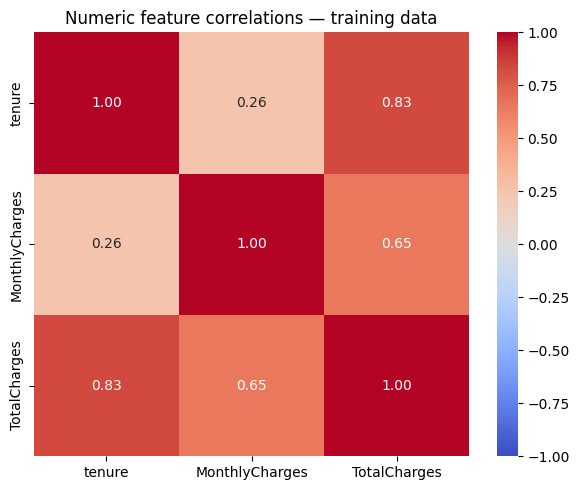

,tenure,MonthlyCharges,TotalCharges
tenure,1.000,0.257,0.829
MonthlyCharges,0.257,1.000,0.654
TotalCharges,0.829,0.654,1.000


In [13]:
numeric_correlations = train_eda[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].corr(method="pearson")

plt.figure(figsize=(6, 5))

sns.heatmap(
    numeric_correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Numeric feature correlations — training data")
plt.tight_layout()
plt.show()

display(numeric_correlations.round(3))

This checks whether numeric inputs overlap in the information they contain. Pandas calculates each correlation using rows where both values are present; we are not imputing values for this chart. A strong correlation alone does not mean we should automatically remove a feature.

differences between customer groups

| Feature | Finding in the training data |
|---|---|
| Contract | Churn is **42.75%** for month-to-month customers, compared with **2.87%** for two-year contracts |
| Internet service | Fibre-optic customers have the highest observed churn rate: **42.09%** |
| Payment method | Electronic-check customers have the highest observed churn rate: **45.74%** |
| Technical support | Churn is **41.75%** without support, compared with **15.16%** with support |
| Numeric relationships | Total charges correlate strongly with tenure (**0.829**) and moderately with monthly charges (**0.654**) |

12. Set the evaluation strategy

Before fixing, need to fix following choices.

| Decision | Approach |
|---|---|
| Positive class | Churn: `1` |
| Primary metric | **F1 for churners**, balancing precision and recall when business costs are unavailable |
| Supporting metrics | Precision, recall, accuracy, ROC-AUC, and average precision |
| Validation | Five-fold stratified cross-validation on training data |
| Initial comparison | Dummy baseline plus the three required models |
| Second experiment | Hyperparameter-tuned versions of the three models |
| Final testing | Evaluate initial and tuned models after all choices are fixed; do not use test results to retune |

F1 gives precision and recall equal importance. We will acknowledge that a real business might prefer a different balance based on retention costs.

13. Define preprocessing pipelines

## Preprocessing and evaluation methodology

Numeric features are tenure, MonthlyCharges, and TotalCharges.
Missing numeric values will be replaced using training-fold
medians. Numeric features will be standardised for KNN and
Logistic Regression.

Categorical features, including SeniorCitizen, will be
one-hot encoded. Valid service-absence categories will be retained.
Random Forest will use imputation and encoding without scaling.

All learned preprocessing will run inside model pipelines.
Five-fold stratified cross-validation will use training data only.
Churn-class F1 is the primary selection metric.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]

categorical_features = [
    column for column in X_train.columns
    if column not in numeric_features
]

def make_preprocessor(scale_numeric=True):
    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_pipeline = Pipeline(numeric_steps)

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Numeric features:", numeric_features)
print("Categorical feature count:", len(categorical_features))
print("Preprocessing and cross-validation defined.")

Numeric features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical feature count: 16
Preprocessing and cross-validation defined.


14. Define the initial models

In [15]:
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

baseline_models = {
    "Dummy": Pipeline([
        ("preprocess", make_preprocessor(scale_numeric=False)),
        ("model", DummyClassifier(strategy="most_frequent"))
    ]),

    "KNN": Pipeline([
        ("preprocess", make_preprocessor(scale_numeric=True)),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Logistic Regression": Pipeline([
        ("preprocess", make_preprocessor(scale_numeric=True)),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocess", make_preprocessor(scale_numeric=False)),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=RANDOM_STATE,
            n_jobs=1
        ))
    ])
}

print("Initial models defined:", list(baseline_models))

Initial models defined: ['Dummy', 'KNN', 'Logistic Regression', 'Random Forest']


15. Run the initial cross-validation experiments

## Experiment 1: Initial model comparison

Evaluate a majority-class dummy baseline, KNN, Logistic
Regression, and Random Forest using the same five stratified
cross-validation folds.

Preprocessing is fitted separately within each fold.
Report mean validation scores and their standard deviations.
The primary comparison metric is F1 for the churn class (1).

In [16]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, pos_label=1, zero_division=0
    ),
    "recall": make_scorer(
        recall_score, pos_label=1, zero_division=0
    ),
    "f1": make_scorer(
        f1_score, pos_label=1, zero_division=0
    ),
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

# Freeze identical folds for all initial and tuned experiments.
cv_splits = list(cv.split(X_train, y_train))

baseline_cv_results = {}
summary_rows = []

for name, pipeline in baseline_models.items():
    print(f"Evaluating {name}...", flush=True)

    results = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv_splits,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1,
        error_score="raise"
    )

    baseline_cv_results[name] = results

    row = {"model": name}

    for metric in scoring:
        scores = results[f"test_{metric}"]
        row[f"{metric}_mean"] = scores.mean()
        row[f"{metric}_std"] = scores.std(ddof=1)

    row["train_f1_mean"] = results["train_f1"].mean()
    row["fit_time_seconds_mean"] = results["fit_time"].mean()

    summary_rows.append(row)

baseline_summary = (
    pd.DataFrame(summary_rows)
    .set_index("model")
    .sort_values("f1_mean", ascending=False)
)

print("\nINITIAL CROSS-VALIDATION RESULTS")
display(baseline_summary.round(4))

Evaluating Dummy...
Evaluating KNN...
Evaluating Logistic Regression...
Evaluating Random Forest...

INITIAL CROSS-VALIDATION RESULTS


,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,train_f1_mean,fit_time_seconds_mean
model,,,,,,,,,,,,,,
Logistic Regression,0.8026,0.0134,0.6547,0.0313,0.5431,0.0460,0.5930,0.0333,0.8461,0.0140,0.6614,0.0216,0.6026,0.1171
KNN,0.7657,0.0058,0.5619,0.0111,0.5311,0.0222,0.5459,0.0153,0.7822,0.0058,0.5070,0.0138,0.6841,0.0762
Random Forest,0.7842,0.0104,0.6232,0.0299,0.4749,0.0289,0.5385,0.0228,0.8178,0.0126,0.6089,0.0307,0.9968,1.1421
Dummy,0.7346,0.0001,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.2654,0.0001,0.0000,0.1906


16. Preserve the results in notebook

In [17]:
# Preserve individual fold scores as well as summary statistics.
fold_rows = []

for name, results in baseline_cv_results.items():
    for fold in range(len(cv_splits)):
        row = {
            "model": name,
            "fold": fold + 1,
            "train_f1": results["train_f1"][fold],
            "fit_time_seconds": results["fit_time"][fold]
        }

        for metric in scoring:
            row[metric] = results[f"test_{metric}"][fold]

        fold_rows.append(row)

baseline_fold_results = pd.DataFrame(fold_rows)

print("INDIVIDUAL FOLD RESULTS")
display(baseline_fold_results.round(4))

INDIVIDUAL FOLD RESULTS


,model,fold,train_f1,fit_time_seconds,accuracy,precision,recall,f1,roc_auc,average_precision
0,Dummy,1,0.0000,0.3858,0.7347,0.0000,0.0000,0.0000,0.5000,0.2653
1,Dummy,2,0.0000,0.3187,0.7347,0.0000,0.0000,0.0000,0.5000,0.2653
2,Dummy,3,0.0000,0.0867,0.7347,0.0000,0.0000,0.0000,0.5000,0.2653
3,Dummy,4,0.0000,0.0812,0.7347,0.0000,0.0000,0.0000,0.5000,0.2653
4,Dummy,5,0.0000,0.0809,0.7345,0.0000,0.0000,0.0000,0.5000,0.2655
5,KNN,1,0.6820,0.0846,0.7613,0.5528,0.5251,0.5386,0.7726,0.4856
6,KNN,2,0.6839,0.0844,0.7640,0.5623,0.4983,0.5284,0.7845,0.5047
7,KNN,3,0.6713,0.0821,0.7746,0.5779,0.5585,0.5680,0.7847,0.5157
8,KNN,4,0.6974,0.0816,0.7604,0.5502,0.5318,0.5408,0.7815,0.5220
9,KNN,5,0.6862,0.0485,0.7682,0.5664,0.5418,0.5538,0.7877,0.5073


According to the results,

Logistic Regression is the strongest initial model, while Random Forest shows a large overfitting gap.

| Model | Validation F1 | Training F1 | Interpretation |
|---|---:|---:|---|
| Logistic Regression | **0.5930** | 0.6026 | Best initial F1, with a small training–validation gap |
| KNN | 0.5459 | 0.6841 | Some overfitting; testing larger neighbourhoods is sensible |
| Random Forest | 0.5385 | 0.9968 | Strong evidence of overfitting; constrain tree complexity |
| Dummy | 0.0000 | 0.0000 | Predicts no churners despite 73.46% accuracy |

Logistic Regression also leads on ROC-AUC and average precision. However, these results do not establish a statistically significant difference, and tuning may change the ranking.

17. Define the tuning searches

| Model | Parameters to explore | Reason |
|---|---|---|
| KNN | Neighbour count, distance weighting, distance measure | Explore smoother predictions and alternative neighbourhood definitions |
| Logistic Regression | Regularisation strength and class weighting | Control complexity and investigate the precision–recall balance |
| Random Forest | Tree depth, minimum leaf size, feature sampling, and class weighting | Reduce overfitting and investigate minority-class performance |

## Experiment 2: Hyperparameter tuning

Tune each required classifier using the same five stratified
training-data folds as Experiment 1. Select configurations
using mean churn-class F1.

KNN tuning explores neighbourhood size, weighting, and distance.
Logistic Regression tuning explores regularisation and class
weighting. Random Forest tuning explores tree complexity,
feature sampling, tree count, and class weighting.

The held-out test set is not used for tuning. The best
cross-validation scores are selection scores and may be
optimistic because the same folds are used to select settings.

In [18]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

knn_grid = {
    "model__n_neighbors": [5, 11, 21, 31, 51],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

logistic_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"]
}

forest_parameters = {
    "model__n_estimators": [100, 300],
    "model__max_depth": [None, 5, 10, 20],
    "model__min_samples_leaf": [1, 5, 10, 20],
    "model__max_features": ["sqrt", 0.5],
    "model__class_weight": [None, "balanced"]
}

searches = {
    "KNN": GridSearchCV(
        estimator=baseline_models["KNN"],
        param_grid=knn_grid,
        scoring=scoring,
        refit="f1",
        cv=cv_splits,
        n_jobs=-1,
        return_train_score=True,
        error_score="raise"
    ),

    "Logistic Regression": GridSearchCV(
        estimator=baseline_models["Logistic Regression"],
        param_grid=logistic_grid,
        scoring=scoring,
        refit="f1",
        cv=cv_splits,
        n_jobs=-1,
        return_train_score=True,
        error_score="raise"
    ),

    "Random Forest": RandomizedSearchCV(
        estimator=baseline_models["Random Forest"],
        param_distributions=forest_parameters,
        n_iter=30,
        scoring=scoring,
        refit="f1",
        cv=cv_splits,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        return_train_score=True,
        error_score="raise"
    )
}

print("Searches defined:")
print("KNN: 20 configurations × 5 folds")
print("Logistic Regression: 10 configurations × 5 folds")
print("Random Forest: 30 sampled configurations × 5 folds")

Searches defined:
KNN: 20 configurations × 5 folds
Logistic Regression: 10 configurations × 5 folds
Random Forest: 30 sampled configurations × 5 folds


C is the inverse of regularisation strength: smaller values impose stronger regularisation. KNN’s p=1 uses Manhattan distance; p=2 uses Euclidean distance. Balanced class weights give greater training weight to the less frequent class, but improvement is not guaranteed.

18. Run tuning and collect results

In [19]:
tuning_rows = []
tuned_models = {}
tuning_results = {}

for name, search in searches.items():
    print(f"Tuning {name}...", flush=True)

    search.fit(X_train, y_train)

    tuned_models[name] = search.best_estimator_
    tuning_results[name] = pd.DataFrame(search.cv_results_)

    best_index = search.best_index_
    results = search.cv_results_

    row = {
        "model": name,
        "best_parameters": search.best_params_
    }

    for metric in scoring:
        row[f"{metric}_mean"] = results[
            f"mean_test_{metric}"
        ][best_index]

    # Use sample standard deviation, matching Experiment 1.
    selected_fold_f1 = [
        results[f"split{fold}_test_f1"][best_index]
        for fold in range(len(cv_splits))
    ]

    row["f1_std"] = np.std(selected_fold_f1, ddof=1)
    row["train_f1_mean"] = results[
        "mean_train_f1"
    ][best_index]

    tuning_rows.append(row)

    print(f"Best CV F1: {search.best_score_:.4f}")
    print("Best parameters:", search.best_params_, "\n")

tuned_summary = (
    pd.DataFrame(tuning_rows)
    .set_index("model")
    .sort_values("f1_mean", ascending=False)
)

print("TUNED CROSS-VALIDATION RESULTS")
display(
    tuned_summary.drop(columns="best_parameters").round(4)
)

Tuning KNN...
Best CV F1: 0.6069
Best parameters: {'model__n_neighbors': 31, 'model__p': 1, 'model__weights': 'uniform'} 

Tuning Logistic Regression...
Best CV F1: 0.6289
Best parameters: {'model__C': 0.1, 'model__class_weight': 'balanced'} 

Tuning Random Forest...
Best CV F1: 0.6358
Best parameters: {'model__n_estimators': 100, 'model__min_samples_leaf': 5, 'model__max_features': 'sqrt', 'model__max_depth': 10, 'model__class_weight': 'balanced'} 

TUNED CROSS-VALIDATION RESULTS


,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,average_precision_mean,f1_std,train_f1_mean
model,,,,,,,,
Random Forest,0.7719,0.5521,0.7505,0.6358,0.8464,0.6572,0.0166,0.7279
Logistic Regression,0.7504,0.5195,0.7973,0.6289,0.8454,0.6592,0.0239,0.6338
KNN,0.7959,0.6202,0.5946,0.6069,0.8335,0.6169,0.0311,0.6299


Tuning improved F1 for all three models. Random Forest is now the selected candidate, based on the highest mean cross-validation F1.

| Model | Initial CV F1 | Tuned CV F1 | Change | Tuned recall |
|---|---:|---:|---:|---:|
| Random Forest | 0.5385 | **0.6358** | +0.0973 | 0.7505 |
| Logistic Regression | 0.5930 | 0.6289 | +0.0359 | **0.7973** |
| KNN | 0.5459 | 0.6069 | +0.0610 | 0.5946 |

Random Forest’s training–validation F1 gap fell from 0.4583 to 0.0921, suggesting that constraining the trees helped reduce overfitting.

There is a trade-off: tuned Logistic Regression identifies more churners, while tuned KNN has higher precision and accuracy. Random Forest leads on our chosen F1 metric, although its 0.0069 advantage over Logistic Regression is small and does not establish statistical superiority.

19. Record the final evaluation plan

## Final held-out evaluation

Random Forest was selected using the highest mean training
cross-validation F1 (0.6358).

Evaluate the dummy baseline and both initial and tuned versions
of the three required classifiers on the same held-out test set.

Use each classifier's predict() decision rule; no decision
threshold optimisation is performed.

Report churn-class precision, recall, F1, accuracy, ROC-AUC,
average precision, and confusion matrices.

Test results will be used for final reporting, not to retune
parameters or change the previously selected model.

20. Evaluate all experimental settings

In [20]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Record the selection made before viewing test results.
selected_model_name = tuned_summary["f1_mean"].idxmax()
print("CV-selected model:", selected_model_name)

test_rows = []
test_predictions = {}
test_probabilities = {}
evaluated_models = {}

experiments = [
    ("Initial", baseline_models),
    ("Tuned", tuned_models)
]

for setting, models in experiments:
    for name, pipeline in models.items():
        label = f"{name} | {setting}"
        print(f"Evaluating {label}...", flush=True)

        # Fit a fresh copy on all training data.
        fitted_model = clone(pipeline)
        fitted_model.fit(X_train, y_train)

        predictions = fitted_model.predict(X_test)

        positive_class_index = list(
            fitted_model.classes_
        ).index(1)

        probabilities = fitted_model.predict_proba(X_test)[
            :, positive_class_index
        ]

        tn, fp, fn, tp = confusion_matrix(
            y_test, predictions, labels=[0, 1]
        ).ravel()

        test_rows.append({
            "model": name,
            "setting": setting,
            "accuracy": accuracy_score(y_test, predictions),
            "precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "f1": f1_score(
                y_test, predictions, zero_division=0
            ),
            "roc_auc": roc_auc_score(
                y_test, probabilities
            ),
            "average_precision": average_precision_score(
                y_test, probabilities
            ),
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp
        })

        evaluated_models[label] = fitted_model
        test_predictions[label] = predictions
        test_probabilities[label] = probabilities

test_summary = (
    pd.DataFrame(test_rows)
    .set_index(["model", "setting"])
)

print("\nHELD-OUT TEST RESULTS")
display(test_summary.round(4))

CV-selected model: Random Forest
Evaluating Dummy | Initial...
Evaluating KNN | Initial...
Evaluating Logistic Regression | Initial...
Evaluating Random Forest | Initial...
Evaluating KNN | Tuned...
Evaluating Logistic Regression | Tuned...
Evaluating Random Forest | Tuned...

HELD-OUT TEST RESULTS


,,accuracy,precision,recall,f1,roc_auc,average_precision,TN,FP,FN,TP
model,setting,,,,,,,,,,
Dummy,Initial,0.7346,0.0000,0.0000,0.0000,0.5000,0.2654,1035,0,374,0
KNN,Initial,0.7573,0.5419,0.5535,0.5476,0.7882,0.5369,860,175,167,207
Logistic Regression,Initial,0.8055,0.6572,0.5588,0.6040,0.8419,0.6338,926,109,165,209
Random Forest,Initial,0.7821,0.6159,0.4759,0.5370,0.8185,0.5996,924,111,196,178
KNN,Tuned,0.7850,0.5983,0.5775,0.5878,0.8280,0.6073,890,145,158,216
Logistic Regression,Tuned,0.7417,0.5087,0.7861,0.6176,0.8407,0.6329,751,284,80,294
Random Forest,Tuned,0.7622,0.5367,0.7620,0.6298,0.8415,0.6527,789,246,89,285


The dummy appears only under “Initial” because it has no tuned version.

21. Visualise the tuned confusion matrices

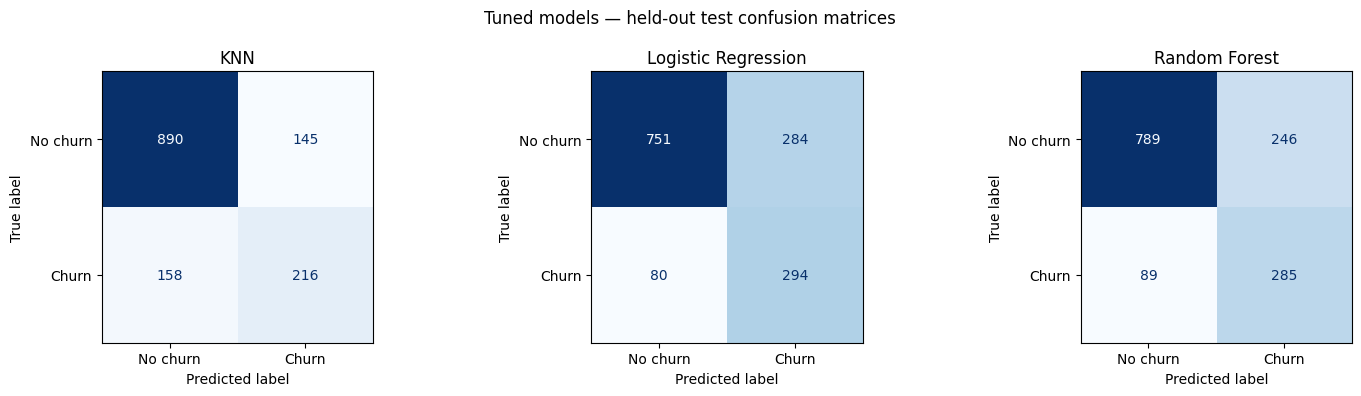

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, name in zip(axes, tuned_models):
    label = f"{name} | Tuned"

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        test_predictions[label],
        labels=[0, 1],
        display_labels=["No churn", "Churn"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(name)

plt.suptitle("Tuned models — held-out test confusion matrices")
plt.tight_layout()
plt.show()

Following are the interpretation of counts

| Count | Meaning | Practical consequence |
|---|---|---|
| TP | Correctly identified a churner | Potential opportunity for retention |
| FN | Missed an actual churner | Customer may leave without intervention |
| FP | Flagged a customer who stayed | Potential unnecessary retention contact or expense |
| TN | Correctly identified a non-churner | No intervention triggered by the model |

These consequences are illustrative; the dataset does not provide actual intervention costs or show whether retention offers would work.